# 04 — Análise de sensibilidade hidrológica
Pergunta: com os dados disponíveis, quais combinações de **evaporação, geometria do espelho d'água e retirada** são compatíveis com a variação observada do armazenamento (afluência implícita ≥ 0)?

`I_implied = ΔV + s·e·A(V) + R` (Z = 0, só dias consecutivos e não saturados). Nada aqui é afluência observada: são **cenários condicionados a hipóteses**.

In [1]:
import sys; sys.path.insert(0, '..')
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from src.data.loaders import load_portal_volume, load_ana_history
from src.hydrology.evaporation import load_power, penman_open_water_mm, evaporation_hm3
from src.hydrology.sensitivity import PROVENANCE, prepare, implied_inflow, grid, A_FULL, K, E_SCALE, R_M3S

vol = load_portal_volume('../data/reserv-ors-capac-175236-portal-hidrologico-ce.csv')
ana = load_ana_history('../data/raw/Histórico_ORÓS.xls')
met = load_power('../data/raw/meteo/nasa_power_oros_daily.json'); met['E_mm_day'] = penman_open_water_mm(met)
x = prepare(vol, met)
pd.Series(PROVENANCE, name='natureza').to_frame()

,natureza
volume_portal,observação (Cogerh/Portal; curva batimétrica; ...
volume_ana,observação (ANA/SAR; curva diferente)
meteorologia,"estimativa (NASA POWER, grade — não é medição ..."
evaporacao_mm,"estimativa (Penman água livre, sem armazenamen..."
area_espelho,hipótese (A = A_full·(V/1940)^k; sem curva cot...
retirada,"hipótese (4,5 / 5,3 m³/s de notícias; outros v..."
vertimento,hipótese (Z = 0; não identificável nos dias sa...


## 1. Portal × ANA (apenas dias em que o Portal não está saturado)

499 dias | diferença Portal−ANA: mediana 37.5 | p5–p95: [0.0, 61.6]


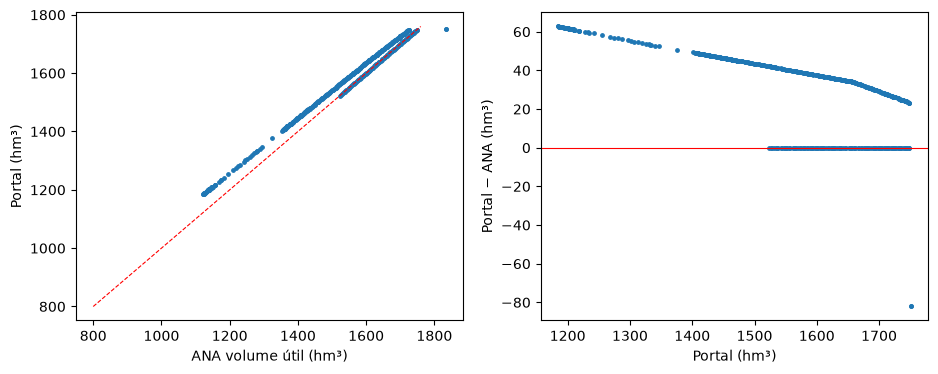

In [2]:
m = vol.merge(ana, on='date'); m = m[m.volume_hm3 < 1752.35]; m['diff'] = m.volume_hm3 - m.useful_volume_hm3
print(len(m), 'dias | diferença Portal−ANA: mediana', round(m['diff'].median(), 1), '| p5–p95:', m['diff'].quantile([.05, .95]).round(1).tolist())
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].scatter(m.useful_volume_hm3, m.volume_hm3, s=6); ax[0].plot([800, 1760], [800, 1760], 'r--', lw=.8)
ax[0].set_xlabel('ANA volume útil (hm³)'); ax[0].set_ylabel('Portal (hm³)')
ax[1].scatter(m.volume_hm3, m['diff'], s=6); ax[1].axhline(0, color='r', lw=.8)
ax[1].set_xlabel('Portal (hm³)'); ax[1].set_ylabel('Portal − ANA (hm³)')
fig.savefig('../results/figures/04_portal_vs_ana_unsaturated.png', dpi=150, bbox_inches='tight')

## 2. Conferência da evaporação (antes de culpar a geometria)
Unidades verificadas no arquivo NASA POWER: radiação **MJ m⁻² dia⁻¹**, T em °C, UR em %, vento 2 m em m/s, pressão em kPa — compatíveis com a equação. O teste unitário confirma 5 mm sobre 100 km² = 0,5 hm³. Persistem como limitações: dados de grade, sem armazenamento de calor, albedo fixo 0,08.

In [3]:
print(met.assign(y=met.date.dt.year).query('2006 < y < 2026').groupby('y').E_mm_day.sum().describe().round(0))

count      19.0
mean     2977.0
std       185.0
min      2652.0
25%      2859.0
50%      3017.0
75%      3095.0
max      3286.0
Name: E_mm_day, dtype: float64


## 3. Grade de sensibilidade
A: 5 × k: 4 × escala de E (0,7–1,3) × R (0; 2,65; 4,5; 5,3 m³/s) = 560 combinações. As escalas são **testes de sensibilidade**, não intervalos de confiança. A coluna "dry" restringe a ago–nov, mês em que se **supõe** afluência regional pequena (hipótese).

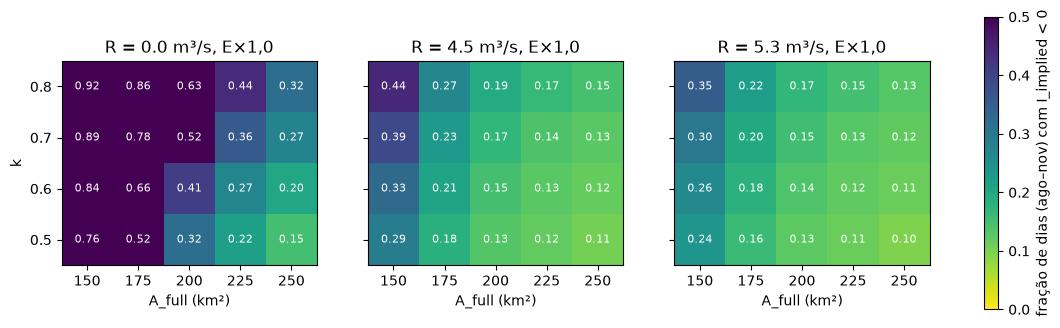

In [4]:
g = grid(x); g.to_csv('../results/sensitivity_grid.csv', index=False)
fig, axs = plt.subplots(1, 3, figsize=(14, 3.8), sharey=True)
for ax, r in zip(axs, (0.0, 4.5, 5.3)):
    p = g[(g.e_scale == 1.0) & (g.r_m3s == r)].pivot(index='k', columns='a_full', values='frac_neg_days_dry')
    im = ax.imshow(p.values, origin='lower', vmin=0, vmax=.5, cmap='viridis_r')
    ax.set_xticks(range(len(p.columns)), p.columns); ax.set_yticks(range(len(p.index)), p.index)
    ax.set_title(f'R = {r} m³/s, E×1,0'); ax.set_xlabel('A_full (km²)')
    for i in range(p.shape[0]):
        for j in range(p.shape[1]): ax.text(j, i, f'{p.values[i, j]:.2f}', ha='center', va='center', color='w', fontsize=8)
axs[0].set_ylabel('k'); fig.colorbar(im, ax=axs, label='fração de dias (ago–nov) com I_implied < 0')
fig.savefig('../results/figures/04_heatmap_negative_inflow.png', dpi=150, bbox_inches='tight')

In [5]:
g.groupby('e_scale')[['frac_neg_days', 'frac_neg_days_dry', 'frac_neg_months_dry']].median().round(3).T

e_scale,0.7,0.8,0.9,1.0,1.1,1.2,1.3
frac_neg_days,0.439,0.352,0.257,0.200,0.154,0.122,0.103
frac_neg_days_dry,0.606,0.432,0.285,0.213,0.173,0.150,0.130
frac_neg_months_dry,0.644,0.506,0.288,0.119,0.056,0.038,0.025


### Leitura correta da restrição I ≥ 0
`I_implied ≥ 0` equivale a `E + R ≥ −ΔV`: ela impõe um **limite inferior** às saídas, não superior. Então **menos negativos com E maior não valida E**: apenas mostra que saídas maiores deixam de contradizer a queda observada. A restrição só descarta combinações de E e R **pequenas demais**. Para limitar E e R por cima seria preciso supor afluência ≈ 0 (hipótese forte) ou ter dados independentes.

O que o limite inferior dá: em cada mês seco, as saídas totais (E + R) foram **pelo menos** a queda do volume.

In [6]:
x['ym'] = x.date.dt.to_period('M'); dry = x[x.date.dt.month.isin([8, 9, 10, 11])]
mm = dry.groupby('ym').agg(dias=('dV', 'size'), queda=('dV', lambda s: -s.sum()))
mm['saida_min_m3s'] = mm.queda / mm.dias / 0.0864
mm = mm[mm.dias >= 25]
print('Saída mínima (E+R) nos meses secos, m³/s — quantis:', mm.saida_min_m3s.quantile([.1, .5, .9, 1]).round(1).tolist())
# comparação com E de cenários + R=0
E_base = evaporation_hm3(dry.E_mm_day, dry.vmean, a_full=200, k=0.7).mean() / 0.0864
print('E média (A200,k0,7,×1) nos meses secos, m³/s:', round(E_base, 1))

Saída mínima (E+R) nos meses secos, m³/s — quantis: [5.6, 15.7, 22.5, 28.4]
E média (A200,k0,7,×1) nos meses secos, m³/s: 14.1


## 4. Cenários experimentais (Z = 0; hipóteses explícitas)
| Cenário | A_full, k | escala E | R (m³/s) |
|---|---|---|---|
| A (baixo) | 150; 0,8 | 0,7 | 2,65 |
| B (intermediário) | 200; 0,7 | 1,0 | 4,5 |
| C (alto) | 250; 0,5 | 1,3 | 5,3 |

Cenário D (vertimento variável em cheias) **não é implementado**: nos dias saturados `I = ΔV + E + R + Z` tem Z desconhecido, então a afluência não é identificável (só limite inferior `I ≥ E + R`).

soma hm³                             frac. dias <0            
          I_A    I_B     I_C dias_validos           I_A   I_B   I_C
date                                                               
2007    233.0  505.0   867.0          365          0.67  0.21  0.01
2008    623.0  840.0  1118.0          256          0.68  0.15  0.03
2009    266.0  482.0   750.0          249          0.61  0.17  0.03
2010     45.0  336.0   707.0          363          0.67  0.23  0.03
2011    540.0  765.0  1045.0          265          0.52  0.11  0.03
2012     59.0  383.0   797.0          366          0.72  0.22  0.04
2013    -87.0  170.0   522.0          357          0.80  0.29  0.05
2014    219.0  465.0   811.0          365          0.63  0.15  0.03
2015    -36.0  186.0   521.0          365          0.79  0.13  0.01
2016    -26.0  167.0   472.0          366          0.64  0.30  0.07
2017    -48.0   87.0   314.0          365          0.53  0.19  0.12
2018    120.0  242.0   446.0          365          0.33  0.01  0.00
2019    116.0  236.0   438.0          365          0.42  0.03  0.00
2020    537.0  708.0   974.0          366          0.49  0.09  0.00
2021    219.0  396.0   661.0          365          0.58  0.11  0.00
2022    651.0  869.0  1173.0          365          0.42  0.09  0.00
2023    452.0  717.0  1070.0          365          0.53  0.12  0.02
2024    425.0  712.0  1089.0          366          0.61  0.15  0.02
2025    545.0  800.0  1125.0          287          0.59  0.12  0.04

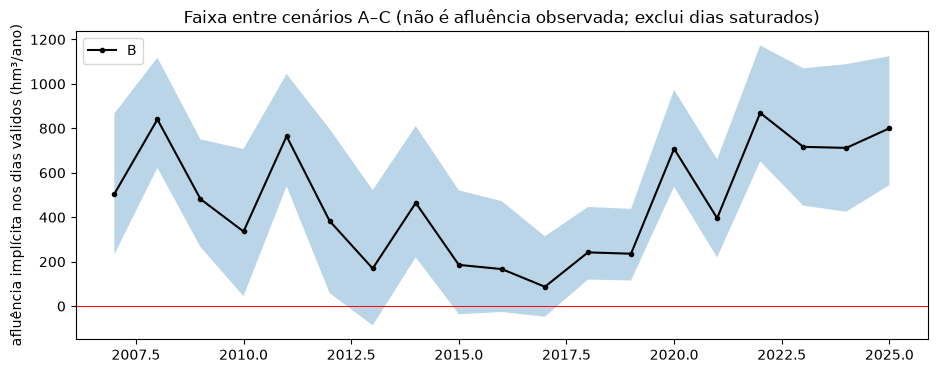

In [7]:
sc = {'A': (150, .8, .7, 2.65), 'B': (200, .7, 1.0, 4.5), 'C': (250, .5, 1.3, 5.3)}
out = {}
for n, args in sc.items():
    x['I_' + n] = implied_inflow(x, *args)
yr = x.groupby(x.date.dt.year)[['I_A', 'I_B', 'I_C']].sum(); yr['dias_validos'] = x.groupby(x.date.dt.year).size()
neg = x.groupby(x.date.dt.year)[['I_A', 'I_B', 'I_C']].agg(lambda s: (s < 0).mean())
fig, ax = plt.subplots(figsize=(11, 4))
yy = yr.loc[2007:2025]
ax.fill_between(yy.index, yy[['I_A', 'I_B', 'I_C']].min(axis=1), yy[['I_A', 'I_B', 'I_C']].max(axis=1), alpha=.3)
ax.plot(yy.index, yy.I_B, 'k-o', ms=3, label='B'); ax.axhline(0, color='r', lw=.7)
ax.set_ylabel('afluência implícita nos dias válidos (hm³/ano)'); ax.legend()
ax.set_title('Faixa entre cenários A–C (não é afluência observada; exclui dias saturados)')
fig.savefig('../results/figures/04_annual_implied_inflow_band.png', dpi=150, bbox_inches='tight')
pd.concat({'soma hm³': yr.round(0), 'frac. dias <0': neg.round(2)}, axis=1).loc[2007:2025]

## 5. Conclusões condicionais (valores desta execução)
- **Compatibilidade só descarta E+R pequenos:** com E×0,7 mediana de 61 % dos dias secos têm I_implied < 0; com E×1,0, 21 %; com E×1,3, 13 %. Em meses secos (ago–nov), a fração de meses com soma negativa cai de 64 % (×0,7) para 12 % (×1,0) e 3 % (×1,3).
- **Limite inferior empírico:** nos meses secos as saídas totais (E+R) foram **pelo menos** ≈ 15,7 m³/s (mediana; 10 %–90 %: 5,6–22,5 m³/s), se a afluência não for negativa. Com R ≤ 5,3 m³/s isso exige E de ordem ≥ 10 m³/s, compatível com Penman×1,0 em A ≈ 200 km².
- **Não identifica um teto:** não há como excluir E maiores nem R diferentes sem supor afluência ≈ 0 ou ter dados independentes.
- **Cenários A–C:** A (E×0,7, R 2,65) gera afluência implícita negativa em vários anos secos (2013, 2015–2017); B e C não. Os totais anuais variam por fator ≈ 2–4 entre cenários: a incerteza hidrológica é **maior que a variabilidade interanual em anos secos**.
- **Limitações:** Z = 0; dias saturados (≈ 7 %) excluídos; geometria hipotética; E por grade; R não observada; ruído diário no volume; ago–nov como "seco" é suposição.
- **Implicação para a pesquisa:** use os cenários como **cenários sintéticos condicionados**, rotulados como tal; não como afluências históricas.